In [ ]:
# Shared bootstrap for notebooks organized by world.
from pathlib import Path
import os, sys
_here = Path.cwd().resolve()
_roots = ( _here, *_here.parents )
_root = next((p for p in _roots if (p / 'pyproject.toml').is_file() and (p / 'src').is_dir()), None)
if _root is None: raise FileNotFoundError('Launch Jupyter from inside the research repository')
if str(_root) not in sys.path: sys.path.insert(0, str(_root))
os.chdir(_root / 'notebooks')  # preserve paths from older notebooks
print('Repository root:', _root)


# Small visual world — exploratory dataset analysis
Inspect the existing small-world dataset *before* interpreting curriculum effects. Scene format: named objects `A/B/C`, each with `color`, `shape`, `size`, `x`, `y`. Questions include `EXISTS_COLOR`, `EXISTS_SHAPE`, `EXISTS_PAIR`, `LEFT`, `ABOVE`, `XOR`, and optional `CLOSER` adaptation. Nested `REF` expressions are parsed as references to exact color–shape combinations.

Each table states its denominator: unique scenes, object occurrences, questions, or question-target pairs. Default splits: `train`, `id_dev`, `ood_dev`, and `adapt_train` if available. Held-out test distributions are excluded by default.

**Visualization update:** Section 1 now uses annotated object-count heatmaps instead of overlapping histograms. Re-run that cell to render the new figure; other saved tables are unaffected.


In [1]:
from pathlib import Path
from collections import Counter
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent
WORLD = 'small'
INCLUDE_HELDOUT = False  # Avoid inspecting test distributions while developing the model.
CANDIDATES = [PROJECT_ROOT/'outputs/dataset', PROJECT_ROOT/'outputs/small_world/dataset', PROJECT_ROOT/'small_world/outputs/dataset', PROJECT_ROOT/'aio_m5_visual_world/outputs/dataset', PROJECT_ROOT/'outputs/pilot']
DATA_DIR = next((p for p in CANDIDATES if (p / 'train.jsonl').exists()), None)
assert DATA_DIR is not None, f'No train.jsonl found. Check paths: {CANDIDATES}'
SPLITS = ['train', 'id_dev', 'ood_dev'] + (['adapt_train'] if WORLD=='small' else [])
if INCLUDE_HELDOUT: SPLITS += ['id_test', 'ood_test'] + (['adapt_test'] if WORLD=='small' else [])
rows = []
for split in SPLITS:
    path = DATA_DIR / f'{split}.jsonl'
    if path.exists():
        with path.open(encoding='utf-8') as file:
            for line in file:
                if line.strip():
                    obj = json.loads(line); obj['_loaded_split'] = split; rows.append(obj)
print('Dataset directory:', DATA_DIR, '| Question rows:', len(rows))
print('Splits:', Counter(r['_loaded_split'] for r in rows))

Dataset directory: c:\Users\Quoc Thai\Downloads\AI\AIO\Conquer\AIO Conquer 5 - visual_world\The-order-of-Learning\outputs\small_world\dataset | Question rows: 2648
Splits: Counter({'train': 1800, 'id_dev': 360, 'ood_dev': 360, 'adapt_train': 128})


In [2]:
def objects_of(scene):
    if isinstance(scene, dict) and isinstance(scene.get('objects'), list):
        return scene['objects']
    if isinstance(scene, dict):
        return [v for v in scene.values() if isinstance(v, dict) and 'color' in v and 'shape' in v]
    raise ValueError(f'Unknown scene representation: {type(scene)}')

def references(question):
    # Capture queried color/shape *pairs* as well as individual attribute queries.
    # Nested REF nodes in small-world LEFT/ABOVE/XOR/CLOSER are handled recursively.
    found=[]
    if not isinstance(question,dict): return found
    op=str(question.get('op','')).upper(); args=question.get('args',[])
    if op in ('REF','EXISTS_PAIR','HAS_COLOR_AND_SHAPE') and len(args)>=2:
        if isinstance(args[0],str) and isinstance(args[1],str):
            found.append(('pair',str(args[0]),str(args[1])))
    elif op=='EXISTS_COLOR' and args and isinstance(args[0],str):
        found.append(('color',str(args[0]),''))
    elif op=='EXISTS_SHAPE' and args and isinstance(args[0],str):
        found.append(('shape',str(args[0]),''))
    for item in args:
        if isinstance(item,dict): found.extend(references(item))
        elif isinstance(item,list):
            for child in item:
                if isinstance(child,dict): found.extend(references(child))
    return found

def requested_attributes(refs):
    colors=set(); shapes=set(); pairs=set()
    for kind,c,s in refs:
        if kind in ('pair','color'): colors.add(c)
        if kind in ('pair','shape'): shapes.add(s if kind=='pair' else c)
        if kind=='pair': pairs.add((c,s))
    return colors,shapes,pairs

def scene_identity(row):
    if row.get('scene_id'): return str(row['scene_id'])
    canonical=json.dumps(row['scene'],sort_keys=True,separators=(',',':'))
    return hashlib.sha1(canonical.encode()).hexdigest()

qrows=[]; scene_records={}; targets=[]; object_records=[]
for row in rows:
    split=row['_loaded_split']; task=str(row.get('template','unknown'))
    scene=row['scene']; obs=objects_of(scene); scene_id=scene_identity(row)
    ocolors=Counter(o['color'] for o in obs); oshapes=Counter(o['shape'] for o in obs)
    opairs=Counter((o['color'],o['shape']) for o in obs)
    refs=references(row.get('question',{})); qc, qs, qp=requested_attributes(refs)
    unique_qc=sorted(qc); unique_qs=sorted(qs); unique_qp=sorted(qp)
    label=int(row['label'])
    key=(split,scene_id)
    if key not in scene_records:
        scene_records[key]={'split':split,'scene_id':scene_id,'n_objects':len(obs),
            'n_unique_colors':len(ocolors),'n_unique_shapes':len(oshapes),
            'repeated_color':int(max(ocolors.values(),default=0)>1),
            'repeated_shape':int(max(oshapes.values(),default=0)>1),
            'n_unique_pairs':len(opairs)}
        for obj in obs:
            object_records.append({'split':split,'scene_id':scene_id, 'color':obj['color'],
                 'shape':obj['shape'],'size':obj.get('size'),
                 'radius':obj.get('radius'),'angle':obj.get('angle')})
    qid=str(row.get('id',f'{split}_{len(qrows)}'))
    qrows.append({'split':split,'scene_id':scene_id,'id':qid,'template':task,
        'op':row.get('question',{}).get('op',''), 'label':label,
        'level':row.get('level'), 'n_objects':len(obs),
        'n_unique_colors':len(ocolors), 'n_unique_shapes':len(oshapes),
        'n_queried_colors':len(qc), 'n_queried_shapes':len(qs), 'n_queried_pairs':len(qp),
        'all_colors_present':all(ocolors[c]>0 for c in qc) if qc else np.nan,
        'all_shapes_present':all(oshapes[s]>0 for s in qs) if qs else np.nan,
        'all_pairs_present':all(opairs[p]>0 for p in qp) if qp else np.nan,
        'any_pairs_present':any(opairs[p]>0 for p in qp) if qp else np.nan,
        'all_reference_pairs_present':all(opairs[p]>0 for p in qp) if qp else np.nan,
        'queried_color':unique_qc[0] if len(qc)==1 else None,
        'queried_shape':unique_qs[0] if len(qs)==1 else None,
        'queried_pair':f'{unique_qp[0][0]} + {unique_qp[0][1]}' if len(qp)==1 else None,
        'heldout_pair':str(row.get('heldout_pair')) if row.get('heldout_pair') else None,
        'closer_margin':row.get('closer_margin'),
        'p_q':str(row.get('p_q')) if row.get('p_q') is not None else None})
    # For target queries, count each requested attribute once per question (not repeated REF occurrences).
    for c in unique_qc:
        targets.append({'split':split,'template':task,'id':qid,'label':label,
                        'kind':'color','target':c,'present':int(ocolors[c]>0),'matches':ocolors[c]})
    for s in unique_qs:
        targets.append({'split':split,'template':task,'id':qid,'label':label,
                        'kind':'shape','target':s,'present':int(oshapes[s]>0),'matches':oshapes[s]})
    for c,s in unique_qp:
        targets.append({'split':split,'template':task,'id':qid,'label':label,
                        'kind':'pair','target':f'{c} + {s}',
                        'present':int(opairs[(c,s)]>0),'matches':opairs[(c,s)]})

questions=pd.DataFrame(qrows);scenes=pd.DataFrame(list(scene_records.values()))
objs=pd.DataFrame(object_records); target_df=pd.DataFrame(targets)
assert len(questions)==len(rows)
assert not scenes.duplicated(['split','scene_id']).any()
print('Questions:',len(questions),'| Unique split/scene records:',len(scenes),
      '| Objects in unique scenes:',len(objs),'| Requested target rows:',len(target_df))

Questions: 2648 | Unique split/scene records: 2648 | Objects in unique scenes: 7944 | Requested target rows: 12536


## 1. Dataset inventory and label balance
**Questions:** How many scenes, question examples, and objects are there? Are classes balanced within every task? Are any scenes reused across questions? We report both scene-unique and question-weighted counts to avoid double counting.

In [3]:
summary=questions.groupby(['split','template']).agg(
    questions=('id','size'),yes_rate=('label','mean'),unique_scenes=('scene_id','nunique'),
    avg_objects=('n_objects','mean')).reset_index()
summary['yes_rate']*=100
print('Counts by split and task (yes_rate in %):');display(summary.round(2))
scene_summary=scenes.groupby('split').agg(unique_scenes=('scene_id','nunique'),
    mean_objects=('n_objects','mean'),mean_unique_colors=('n_unique_colors','mean'),
    mean_unique_shapes=('n_unique_shapes','mean')).round(2)
print('Scene-weighted statistics:');display(scene_summary)
print('Questions per scene (within split):')
display(questions.groupby(['split','scene_id']).size().groupby('split').value_counts().rename('number_of_scenes').to_frame())
print('Scene-ID overlap across splits:')
for i,a in enumerate(questions.split.unique()):
    for b in questions.split.unique()[i+1:]:
        overlap=len(set(scenes.loc[scenes.split==a,'scene_id']) & set(scenes.loc[scenes.split==b,'scene_id']))
        print(f'  {a} vs {b}: {overlap}')

Counts by split and task (yes_rate in %):


,split,template,questions,yes_rate,unique_scenes,avg_objects
0,adapt_train,closer,128,50.0,128,3.0
1,id_dev,above,60,50.0,60,3.0
2,id_dev,color,40,50.0,40,3.0
3,id_dev,left,60,50.0,60,3.0
4,id_dev,pair,40,50.0,40,3.0
5,id_dev,shape,40,50.0,40,3.0
6,id_dev,xor,120,50.0,120,3.0
7,ood_dev,above,60,50.0,60,3.0
8,ood_dev,left,60,50.0,60,3.0
9,ood_dev,pair,120,50.0,120,3.0


Scene-weighted statistics:


,unique_scenes,mean_objects,mean_unique_colors,mean_unique_shapes
split,,,,
adapt_train,128,3.0,2.0,2.0
id_dev,360,3.0,2.0,2.0
ood_dev,360,3.0,2.0,2.0
train,1800,3.0,2.0,2.0


Questions per scene (within split):


,,number_of_scenes
split,,
adapt_train,1,128
id_dev,1,360
ood_dev,1,360
train,1,1800


Scene-ID overlap across splits:
  train vs id_dev: 0
  train vs ood_dev: 0
  train vs adapt_train: 0
  id_dev vs ood_dev: 0
  id_dev vs adapt_train: 0
  ood_dev vs adapt_train: 0


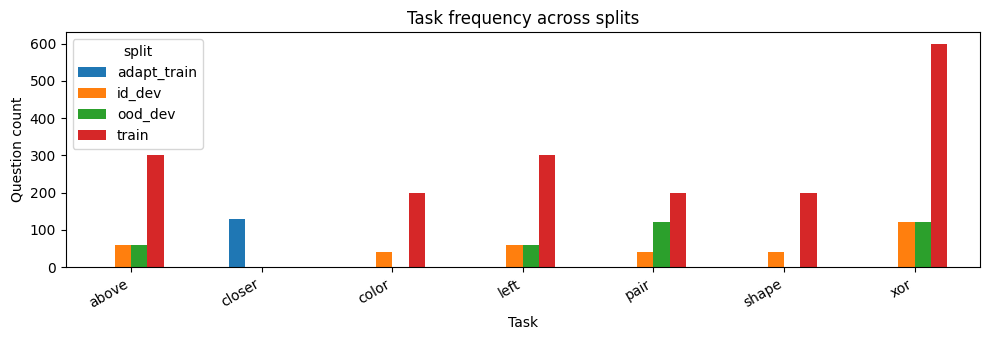

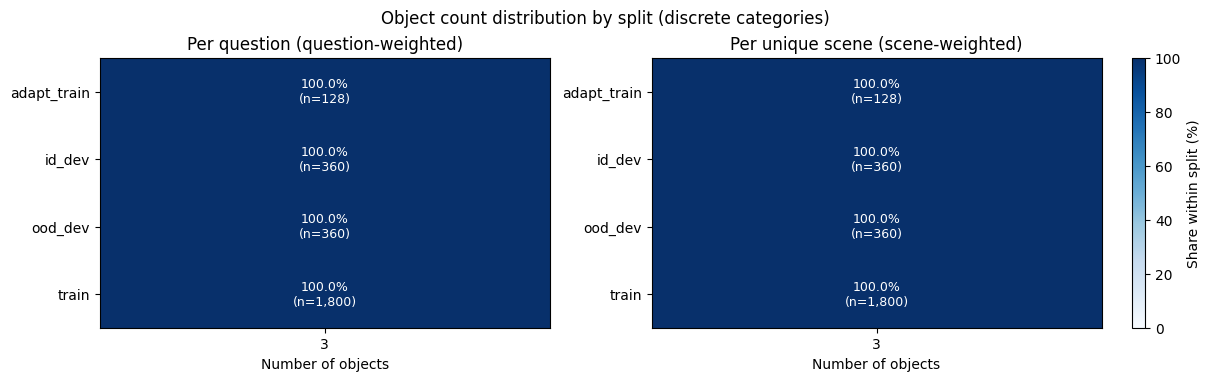

In [4]:
fig,ax=plt.subplots(figsize=(10,3.5))
tab=pd.crosstab(questions['template'],questions['split']).sort_index()
tab.plot(kind='bar',ax=ax);ax.set_ylabel('Question count');ax.set_xlabel('Task')
ax.set_title('Task frequency across splits');plt.xticks(rotation=30,ha='right');plt.tight_layout();plt.show()

# Clear, non-overlapping display: annotated heatmaps of discrete object counts.
# Question-weighted and unique-scene-weighted distributions can differ when scenes are reused.
fig, ax = plt.subplots(1, 2, figsize=(12, max(3.3, 0.55*questions.split.nunique()+1.5)), constrained_layout=True)
for a, (df, title) in zip(ax, [
    (questions, 'Per question (question-weighted)'),
    (scenes, 'Per unique scene (scene-weighted)')
]):
    counts = pd.crosstab(df['split'], df['n_objects']).sort_index()
    counts = counts.reindex(columns=sorted(set(questions.n_objects) | set(scenes.n_objects)), fill_value=0)
    percentages = counts.div(counts.sum(axis=1), axis=0).mul(100)
    im = a.imshow(percentages.to_numpy(), aspect='auto', vmin=0, vmax=100, cmap='Blues')
    a.set_xticks(range(len(counts.columns)), [str(x) for x in counts.columns])
    a.set_yticks(range(len(counts.index)), counts.index)
    a.set_xlabel('Number of objects'); a.set_title(title)
    for row in range(len(counts.index)):
        for col in range(len(counts.columns)):
            value = percentages.iat[row, col]
            a.text(col, row, f'{value:.1f}%\n(n={counts.iat[row,col]:,})',
                   ha='center', va='center', fontsize=9,
                   color='white' if value >= 55 else 'black')
fig.suptitle('Object count distribution by split (discrete categories)', fontsize=12)
fig.colorbar(im, ax=ax, label='Share within split (%)', fraction=.035, pad=.03)
plt.show()


## 2. Which colors and shapes actually appear?
**Questions:** What colors/shapes are most common in the image? Which combinations occur? Is an attribute present in many scenes because it repeats within scenes? Object counts below are **deduplicated by scene**. The second table reports the probability a unique scene contains an attribute.


COLOR: object occurrence counts


split,adapt_train,id_dev,ood_dev,train
color,,,,
blue,60,232,331,1067
green,82,191,254,1015
red,69,249,338,1087
yellow,173,408,157,2231


COLOR: % of unique scenes containing it


color,blue,green,red,yellow
split,,,,
adapt_train,35.2,46.1,39.1,79.7
id_dev,44.2,39.2,45.8,70.8
ood_dev,57.2,48.6,58.3,35.8
train,41.7,40.4,42.3,75.5


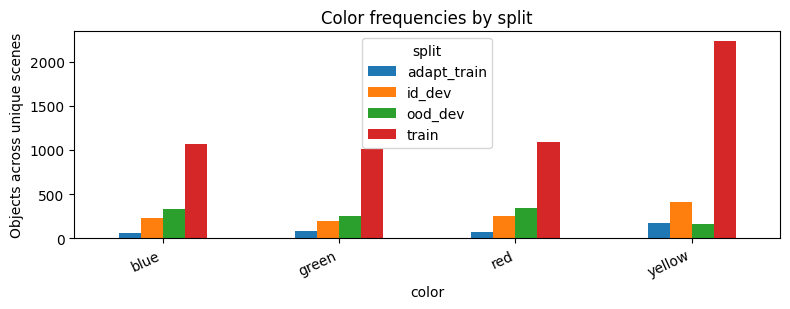


SHAPE: object occurrence counts


split,adapt_train,id_dev,ood_dev,train
shape,,,,
circle,109,377,312,1849
square,139,364,394,1797
triangle,136,339,374,1754


SHAPE: % of unique scenes containing it


shape,circle,square,triangle
split,,,
adapt_train,63.3,68.8,68.0
id_dev,71.4,67.2,61.4
ood_dev,62.2,70.8,66.9
train,68.1,66.5,65.4


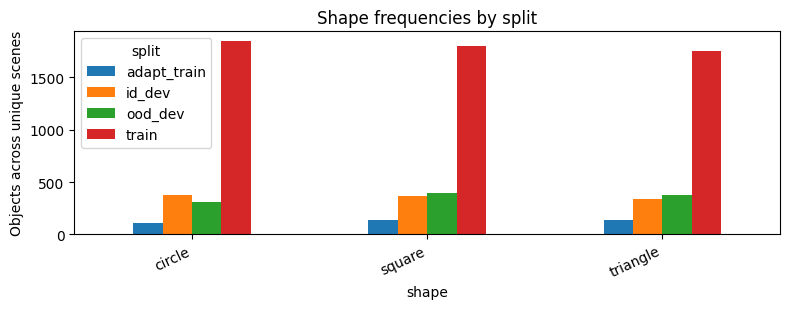

Object-level color × shape counts (train scenes):


shape,circle,square,triangle
color,,,
blue,545,0,522
green,0,511,504
red,553,534,0
yellow,751,752,728


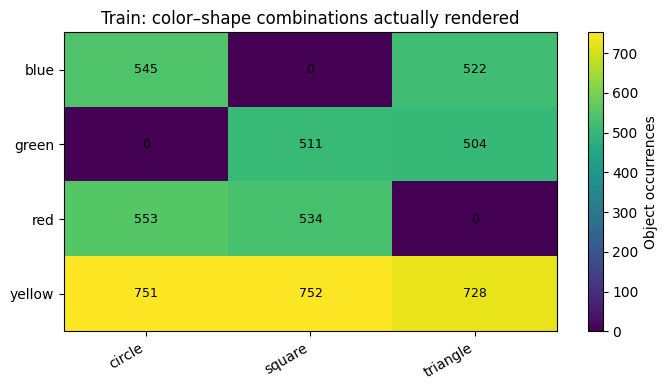

In [5]:
for attribute in ['color','shape']:
    counts=pd.crosstab(objs[attribute],objs['split'])
    pres=(objs.drop_duplicates(['split','scene_id',attribute])
           .groupby(['split',attribute]).size().unstack(fill_value=0))
    pres=pres.div(scenes.groupby('split').size(),axis=0).mul(100)
    print(f'\n{attribute.upper()}: object occurrence counts');display(counts)
    print(f'{attribute.upper()}: % of unique scenes containing it');display(pres.round(1))
    fig,ax=plt.subplots(figsize=(8,3.2))
    counts.plot(kind='bar',ax=ax)
    ax.set_ylabel('Objects across unique scenes');ax.set_title(f'{attribute.title()} frequencies by split')
    plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()
print('Object-level color × shape counts (train scenes):')
cooccur=pd.crosstab(objs.loc[objs.split=='train','color'],objs.loc[objs.split=='train','shape'])
display(cooccur)
fig,ax=plt.subplots(figsize=(7,4))
im=ax.imshow(cooccur.values,aspect='auto')
ax.set_xticks(range(len(cooccur.columns)),cooccur.columns,rotation=30,ha='right')
ax.set_yticks(range(len(cooccur.index)),cooccur.index)
ax.set_title('Train: color–shape combinations actually rendered')
for i in range(cooccur.shape[0]):
    for j in range(cooccur.shape[1]):ax.text(j,i,str(cooccur.iloc[i,j]),ha='center',va='center',fontsize=9)
plt.colorbar(im,ax=ax,label='Object occurrences');plt.tight_layout();plt.show()

## 3. What attributes are being asked?
**Questions:** Do question generators favor particular colors, shapes or pairs? Does the distribution change by task or split? Nested small-world questions may request multiple distinct attributes, so totals can exceed the number of questions. Repeated references to the same attribute within one question are counted once.


Requested color targets by task (train):


template,above,color,left,pair,xor
target,,,,,
blue,126,50,52,46,252
green,124,50,48,44,248
red,130,50,56,44,260
yellow,220,50,144,66,440


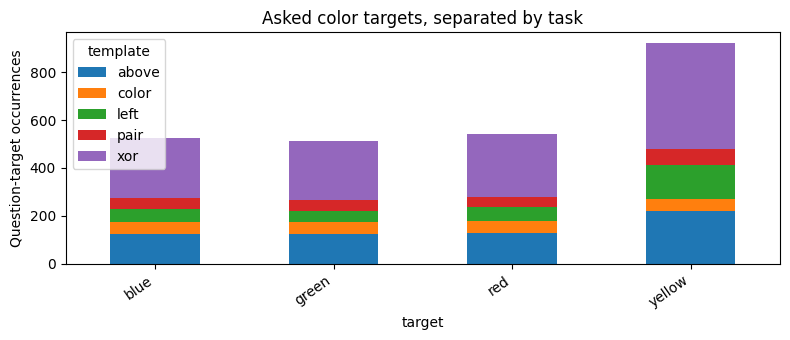


Requested shape targets by task (train):


template,above,left,pair,shape,xor
target,,,,,
circle,102,204,68,68,408
square,100,200,66,66,400
triangle,98,196,66,66,392


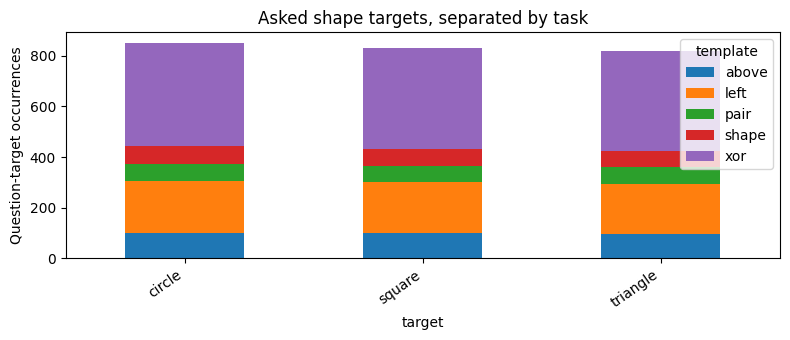


Requested pair targets by task (train):


template,above,left,pair,xor
target,,,,
blue + circle,64,52,24,180
blue + triangle,62,52,22,176
green + square,62,48,22,172
green + triangle,62,48,22,172
red + circle,66,56,22,188
red + square,64,56,22,184
yellow + circle,74,96,22,244
yellow + square,74,96,22,244
yellow + triangle,72,96,22,240


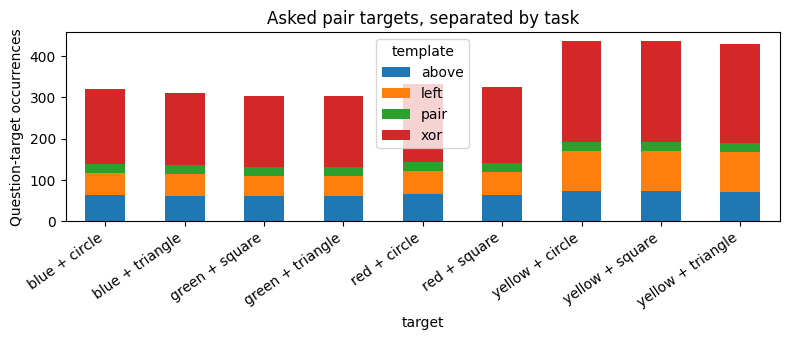

Number of DISTINCT queried attributes per question:


n_queried_colors  n_queried_shapes  n_queried_pairs
split       template                                                     
adapt_train closer                 2.0               2.0              3.0
id_dev      above                  2.0               1.0              2.0
            color                  1.0               0.0              0.0
            left                   1.0               2.0              2.0
            pair                   1.0               1.0              1.0
            shape                  0.0               1.0              0.0
            xor                    2.0               2.0              3.0
ood_dev     above                  2.0               1.0              2.0
            left                   1.0               2.0              2.0
            pair                   1.0               1.0              1.0
            xor                    2.0               2.0              3.0
train       above                  2.0               1.0              2.0
            color                  1.0               0.0              0.0
            left                   1.0               2.0              2.0
            pair                   1.0               1.0              1.0
            shape                  0.0               1.0              0.0
            xor                    2.0               2.0              3.0

In [6]:
for kind in ['color','shape','pair']:
    part=target_df[(target_df.kind==kind) & (target_df.split=='train')]
    if part.empty:continue
    frequency=pd.crosstab(part['target'],part['template'])
    print(f'\nRequested {kind} targets by task (train):');display(frequency)
    fig,ax=plt.subplots(figsize=(max(8,0.6*len(frequency)),3.5))
    frequency.plot(kind='bar',stacked=True,ax=ax)
    ax.set_ylabel('Question-target occurrences');ax.set_title(f'Asked {kind} targets, separated by task')
    plt.xticks(rotation=35,ha='right');plt.tight_layout();plt.show()
print('Number of DISTINCT queried attributes per question:')
display(questions.groupby(['split','template'])[['n_queried_colors','n_queried_shapes','n_queried_pairs']].mean().round(2))

## 4. Does an asked attribute actually appear in the scene?
**Questions:** Given that a question asks about *red*, how often is there red in the image? What changes for negative vs positive labels, and for different tasks? These are conditional rates over **question-target pairs**, not unconditional prevalence. For `LEFT`/`XOR`/`CLOSER`, presence alone is insufficient to determine the answer.

Presence of asked attributes, separated by split, task and label:


,split,template,kind,label,n,present_pct,avg_matches
0,adapt_train,closer,color,0,128,100.0,1.5
1,adapt_train,closer,color,1,128,100.0,1.5
2,adapt_train,closer,pair,0,192,100.0,1.0
3,adapt_train,closer,pair,1,192,100.0,1.0
4,adapt_train,closer,shape,0,128,100.0,1.5
...,...,...,...,...,...,...,...
81,train,xor,color,1,600,100.0,1.5
82,train,xor,pair,0,900,100.0,1.0
83,train,xor,pair,1,900,100.0,1.0
84,train,xor,shape,0,600,100.0,1.5



P(requested color present | task, label), train:


label,0,1
template,,
above,100.0,100.0
color,0.0,100.0
left,100.0,100.0
pair,100.0,100.0
xor,100.0,100.0


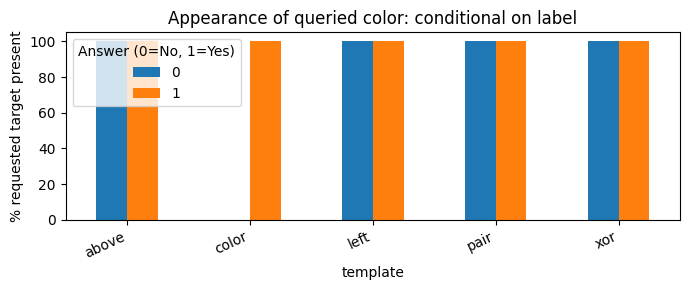


P(requested shape present | task, label), train:


label,0,1
template,,
above,100.0,100.0
left,100.0,100.0
pair,100.0,100.0
shape,0.0,100.0
xor,100.0,100.0


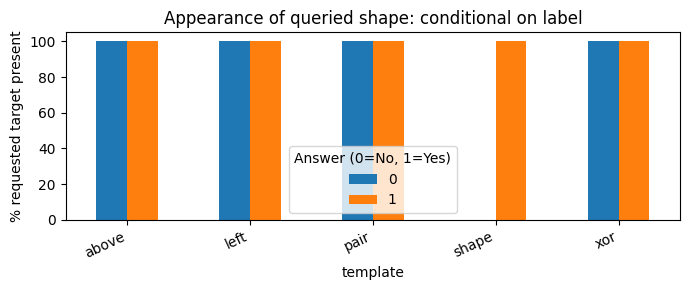


P(requested pair present | task, label), train:


label,0,1
template,,
above,100.0,100.0
left,100.0,100.0
pair,0.0,100.0
xor,100.0,100.0


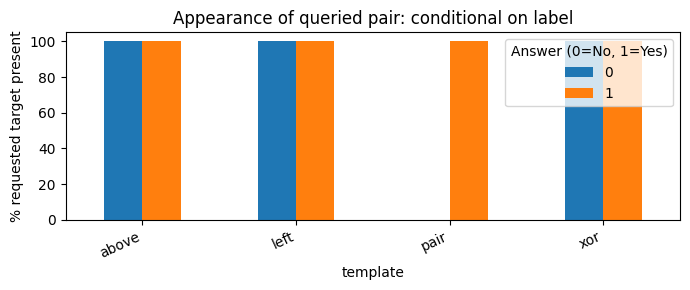

In [7]:
presence=(target_df.groupby(['split','template','kind','label'])
          .agg(n=('present','size'),present_pct=('present',lambda x:100*x.mean()),
               avg_matches=('matches','mean')).reset_index())
print('Presence of asked attributes, separated by split, task and label:')
display(presence.round(2))
for kind in ['color','shape','pair']:
    part=target_df[(target_df.split=='train')&(target_df.kind==kind)]
    if part.empty: continue
    h=part.groupby(['template','label'])['present'].mean().unstack()
    print(f'\nP(requested {kind} present | task, label), train:')
    display((100*h).round(1))
    fig,ax=plt.subplots(figsize=(max(7,len(h)*1.2),3))
    h.mul(100).plot(kind='bar',ax=ax)
    ax.set_ylabel('% requested target present');ax.set_ylim(0,105)
    ax.set_title(f'Appearance of queried {kind}: conditional on label')
    ax.legend(title='Answer (0=No, 1=Yes)');plt.xticks(rotation=25,ha='right');plt.tight_layout();plt.show()

## 5. Can the answer be guessed from the question alone?
**Questions:** Does asking about blue, a square, or a particular pair make `Yes` more likely? The table below shows per-target `Yes` rates and deviation from the task's overall `Yes` rate. An attribute can occur in multiple question targets; this is exploratory, not a trained classifier.

In [8]:
qbase=questions.groupby(['split','template'])['label'].mean().rename('task_yes_rate')
leak=(target_df.groupby(['split','template','kind','target'])['label']
      .agg(n='size',yes_rate='mean').reset_index()
      .merge(qbase.reset_index(),on=['split','template'],how='left'))
leak['shift_percentage_points']=100*(leak['yes_rate']-leak['task_yes_rate'])
subset=leak[(leak.split=='train')&(leak.n>=10)].copy()
if len(subset):
    ranked=subset.reindex(subset.shift_percentage_points.abs().sort_values(ascending=False).index)
    print('Top question-target/label associations (train, minimum 10 questions):')
    display(ranked.head(25).round(2))
else: print('Too few repeated targets for the n>=10 display threshold.')
print('Task baseline Yes rates:')
display((100*qbase).round(1).rename('yes_rate_pct').to_frame())

Top question-target/label associations (train, minimum 10 questions):


,split,template,kind,target,n,yes_rate,task_yes_rate,shift_percentage_points
149,train,above,color,blue,126,0.5,0.5,0.0
150,train,above,color,green,124,0.5,0.5,0.0
151,train,above,color,red,130,0.5,0.5,0.0
152,train,above,color,yellow,220,0.5,0.5,0.0
153,train,above,pair,blue + circle,64,0.5,0.5,0.0
154,train,above,pair,blue + triangle,62,0.5,0.5,0.0
155,train,above,pair,green + square,62,0.5,0.5,0.0
156,train,above,pair,green + triangle,62,0.5,0.5,0.0
157,train,above,pair,red + circle,66,0.5,0.5,0.0
158,train,above,pair,red + square,64,0.5,0.5,0.0


Task baseline Yes rates:


yes_rate_pct
split       template              
adapt_train closer            50.0
id_dev      above             50.0
            color             50.0
            left              50.0
            pair              50.0
            shape             50.0
            xor               50.0
ood_dev     above             50.0
            left              50.0
            pair              50.0
            xor               50.0
train       above             50.0
            color             50.0
            left              50.0
            pair              50.0
            shape             50.0
            xor               50.0

## 6. Task-specific logical shortcuts (color, shape, conjunction, pair)
For a simple `conjunction`, a positive answer needs **both** attributes somewhere; `pair` needs them on the **same object**. `color-only` and `shape-only` rules are shortcuts, not model predictions. For other relational tasks, the table is not applicable.

In [9]:
simple_ops={'EXISTS_COLOR','EXISTS_SHAPE','EXISTS_PAIR','HAS_COLOR_AND_SHAPE'}
simple=questions[questions.op.isin(simple_ops)].copy()
if len(simple):
    def logical_answer(r):
        if r.op=='EXISTS_COLOR': return int(bool(r.all_colors_present))
        if r.op=='EXISTS_SHAPE': return int(bool(r.all_shapes_present))
        if r.op=='HAS_COLOR_AND_SHAPE':return int(bool(r.all_colors_present) and bool(r.all_shapes_present))
        if r.op=='EXISTS_PAIR':return int(bool(r.all_pairs_present))
        return np.nan
    simple['oracle_from_scene']=simple.apply(logical_answer,axis=1)
    mismatch=simple[simple.oracle_from_scene != simple.label]
    print('Scene-derived oracle mismatch:',len(mismatch),'/',len(simple))
    if len(mismatch):display(mismatch[['split','template','id','label','oracle_from_scene']].head())
    for op in ['HAS_COLOR_AND_SHAPE','EXISTS_PAIR']:
        ss=simple[simple.op==op].copy()
        if ss.empty:continue
        ss['color_only']=ss.all_colors_present.astype(int)
        ss['shape_only']=ss.all_shapes_present.astype(int)
        ss['both_attrs_present']=(ss.all_colors_present & ss.all_shapes_present).astype(int)
        ss['pair_present']=ss.any_pairs_present.astype(int)
        print(f'\n{op}: shortcut accuracy and hard-negative frequency by split:')
        table=ss.groupby('split').apply(lambda x:pd.Series({
            'questions':len(x),'color_only_acc':(x.color_only==x.label).mean(),
            'shape_only_acc':(x.shape_only==x.label).mean(),
            'both_present_acc':(x.both_attrs_present==x.label).mean(),
            'negative_both_attrs_pct':100*((x.label==0)&(x.both_attrs_present==1)).sum()/max((x.label==0).sum(),1),
            'negative_pair_absent_pct':100*((x.label==0)&(x.pair_present==0)).sum()/max((x.label==0).sum(),1)
        }),include_groups=False)
        display(table.round(3))
else:print('No simple existence-type questions in loaded splits.')

Scene-derived oracle mismatch: 0 / 840

EXISTS_PAIR: shortcut accuracy and hard-negative frequency by split:


,questions,color_only_acc,shape_only_acc,both_present_acc,negative_both_attrs_pct,negative_pair_absent_pct
split,,,,,,
id_dev,40.0,0.5,0.5,0.5,100.0,100.0
ood_dev,120.0,0.5,0.5,0.5,100.0,100.0
train,200.0,0.5,0.5,0.5,100.0,100.0


## 7. What makes the scene harder?
Report object count, repeated colors, and repeated shapes by task and label. These factors may affect visual ambiguity even when labels are balanced. Medium-world size/angle/radius are available at object level; small-world has a small/large size categorical attribute.

In [10]:
print('Scene structural difficulty (unique scenes):')
display(scenes.groupby('split')[['n_objects','n_unique_colors','n_unique_shapes','repeated_color','repeated_shape']].agg(['mean','std']).round(2))
print('Object count by task and label (question weighted):')
display(questions.groupby(['split','template','label'])['n_objects'].agg(['count','mean','std']).round(2))
for field in ['size','radius','angle']:
    if objs[field].notna().any():
        print(f'\nObject {field} distribution by split:')
        display(pd.crosstab(objs[field],objs.split))

Scene structural difficulty (unique scenes):


n_objects      n_unique_colors      n_unique_shapes       \
                 mean  std            mean  std            mean  std   
split                                                                  
adapt_train       3.0  0.0             2.0  0.0             2.0  0.0   
id_dev            3.0  0.0             2.0  0.0             2.0  0.0   
ood_dev           3.0  0.0             2.0  0.0             2.0  0.0   
train             3.0  0.0             2.0  0.0             2.0  0.0   

            repeated_color      repeated_shape       
                      mean  std           mean  std  
split                                                
adapt_train            1.0  0.0            1.0  0.0  
id_dev                 1.0  0.0            1.0  0.0  
ood_dev                1.0  0.0            1.0  0.0  
train                  1.0  0.0            1.0  0.0

Object count by task and label (question weighted):


count  mean  std
split       template label                  
adapt_train closer   0         64   3.0  0.0
                     1         64   3.0  0.0
id_dev      above    0         30   3.0  0.0
                     1         30   3.0  0.0
            color    0         20   3.0  0.0
                     1         20   3.0  0.0
            left     0         30   3.0  0.0
                     1         30   3.0  0.0
            pair     0         20   3.0  0.0
                     1         20   3.0  0.0
            shape    0         20   3.0  0.0
                     1         20   3.0  0.0
            xor      0         60   3.0  0.0
                     1         60   3.0  0.0
ood_dev     above    0         30   3.0  0.0
                     1         30   3.0  0.0
            left     0         30   3.0  0.0
                     1         30   3.0  0.0
            pair     0         60   3.0  0.0
                     1         60   3.0  0.0
            xor      0         60   3.0  0.0
                     1         60   3.0  0.0
train       above    0        150   3.0  0.0
                     1        150   3.0  0.0
            color    0        100   3.0  0.0
                     1        100   3.0  0.0
            left     0        150   3.0  0.0
                     1        150   3.0  0.0
            pair     0        100   3.0  0.0
                     1        100   3.0  0.0
            shape    0        100   3.0  0.0
                     1        100   3.0  0.0
            xor      0        300   3.0  0.0
                     1        300   3.0  0.0


Object size distribution by split:


split,adapt_train,id_dev,ood_dev,train
size,,,,
large,205,526,531,2711
small,179,554,549,2689


## 8. OOD and held-out combination audit
Compare appearance of queried color–shape combinations across splits. These tables can reveal whether OOD development actually asks about unseen combinations and whether those combinations appear as objects in the train scenes. This is an audit of the **dataset**, not an evaluation of a model.

In [11]:
print('Pair combinations requested, by task and split:')
pp=target_df[target_df.kind=='pair']
if len(pp):
    display(pd.crosstab([pp.template,pp.target],pp.split))
    display(pp.groupby(['split','template'])['present'].agg(['size','mean']).round(3))
print('Pairs actually present as objects in unique scenes, by split:')
comb=objs.assign(pair=objs.color+' + '+objs['shape'])
display(pd.crosstab(comb.pair,comb.split))
metadata_path=DATA_DIR/'dataset_metadata.json'
if metadata_path.exists():
    metadata=json.loads(metadata_path.read_text(encoding='utf-8'))
    heldout=metadata.get('heldout_pairs',metadata.get('config',{}).get('holdout'))
    print('Held-out pairs declared by dataset metadata:',heldout)
    if heldout:
        for c,s in heldout:
            k=f'{c} + {s}'
            seen=comb[comb.pair==k].groupby('split').size().to_dict()
            asked=pp[pp.target==k].groupby('split').size().to_dict()
            print(f'{k}: rendered object occurrences={seen}, question targets={asked}')
if questions.heldout_pair.notna().any():
    print('Record-level heldout_pair tags:')
    display(pd.crosstab(questions.heldout_pair,questions.split))

Pair combinations requested, by task and split:


split                       adapt_train  id_dev  ood_dev  train
template target                                                
above    blue + circle                0      14        4     64
         blue + square                0       0       24      0
         blue + triangle              0      12        8     62
         green + circle               0       0       12      0
         green + square               0      12        8     62
         green + triangle             0      12        8     62
         red + circle                 0      16        4     66
         red + square                 0      14        8     64
         red + triangle               0       0       24      0
         yellow + circle              0      14        4     74
         yellow + square              0      14        8     74
         yellow + triangle            0      12        8     72
closer   blue + circle               28       0        0      0
         blue + triangle             32       0        0      0
         green + square              38       0        0      0
         green + triangle            44       0        0      0
         red + circle                25       0        0      0
         red + square                44       0        0      0
         yellow + circle             56       0        0      0
         yellow + square             57       0        0      0
         yellow + triangle           60       0        0      0
left     blue + circle                0      12       12     52
         blue + square                0       0       24      0
         blue + triangle              0      12       12     52
         green + circle               0       0       12      0
         green + square               0       8        6     48
         green + triangle             0       8        6     48
         red + circle                 0      16       12     56
         red + square                 0      16       12     56
         red + triangle               0       0       24      0
         yellow + circle              0      16        0     96
         yellow + square              0      16        0     96
         yellow + triangle            0      16        0     96
pair     blue + circle                0       6        0     24
         blue + square                0       0       40      0
         blue + triangle              0       6        0     22
         green + circle               0       0       40      0
         green + square               0       4        0     22
         green + triangle             0       4        0     22
         red + circle                 0       4        0     22
         red + square                 0       4        0     22
         red + triangle               0       0       40      0
         yellow + circle              0       4        0     22
         yellow + square              0       4        0     22
         yellow + triangle            0       4        0     22
xor      blue + circle                0      40       32    180
         blue + square                0       0       48      0
         blue + triangle              0      36       40    176
         green + circle               0       0       24      0
         green + square               0      32       28    172
         green + triangle             0      32       28    172
         red + circle                 0      48       32    188
         red + square                 0      44       40    184
         red + triangle               0       0       48      0
         yellow + circle              0      44        8    244
         yellow + square              0      44       16    244
         yellow + triangle            0      40       16    240

size  mean
split       template            
adapt_train closer     384   1.0
id_dev      above      120   1.0
            left       120   1.0
            pair        40   0.5
            xor        360   1.0
ood_dev     above      120   1.0
            left       120   1.0
            pair       120   0.5
            xor        360   1.0
train       above      600   1.0
            left       600   1.0
            pair       200   0.5
            xor       1800   1.0

Pairs actually present as objects in unique scenes, by split:


split,adapt_train,id_dev,ood_dev,train
pair,,,,
blue + circle,28,119,100,545
blue + square,0,0,116,0
blue + triangle,32,113,115,522
green + circle,0,0,68,0
green + square,38,96,99,511
green + triangle,44,95,87,504
red + circle,25,124,101,553
red + square,44,125,121,534
red + triangle,0,0,116,0


Held-out pairs declared by dataset metadata: [['blue', 'square'], ['green', 'circle'], ['red', 'triangle']]
blue + square: rendered object occurrences={'ood_dev': 116}, question targets={'ood_dev': 136}
green + circle: rendered object occurrences={'ood_dev': 68}, question targets={'ood_dev': 88}
red + triangle: rendered object occurrences={'ood_dev': 116}, question targets={'ood_dev': 136}
Record-level heldout_pair tags:


split,ood_dev
heldout_pair,
"['blue', 'square']",136
"['green', 'circle']",88
"['red', 'triangle']",136


## 10. Small-world relational-task details
Check whether `LEFT`, `ABOVE`, `XOR`, and `CLOSER` questions systematically favor particular reference colors or shapes. XOR `p_q` records the source generator's two subquestion labels; `closer_margin` is available in adaptation records. These fields are analyzed without inventing a new semantic interpretation.

In [12]:
rel=questions[questions.template.isin(['left','above','xor','closer'])].copy()
if len(rel):
    print('Reference-target presence by relational operator:')
    display(target_df[target_df.template.isin(['left','above','xor','closer'])]
            .groupby(['split','template','kind'])['present'].agg(['size','mean']).round(3))
    for name in ['left','above','xor','closer']:
        ss=rel[rel.template==name]
        if len(ss):
            print(f'{name}:',len(ss),'questions, average distinct reference pairs=',round(ss.n_queried_pairs.mean(),2))
    xor=questions[(questions.template=='xor') & questions.p_q.notna()]
    if len(xor):
        print('XOR subquestion-label combinations, by answer:')
        display(pd.crosstab([xor.split,xor.p_q],xor.label))
    closer=questions[(questions.template=='closer') & questions.closer_margin.notna()]
    if len(closer):
        print('CLOSER margin by answer:')
        display(closer.groupby(['split','label']).closer_margin.agg(['count','min','median','max']).round(2))
else: print('No relational tasks in these splits.')

Reference-target presence by relational operator:


size  mean
split       template kind             
adapt_train closer   color   256   1.0
                     pair    384   1.0
                     shape   256   1.0
id_dev      above    color   120   1.0
                     pair    120   1.0
                     shape    60   1.0
            left     color    60   1.0
                     pair    120   1.0
                     shape   120   1.0
            xor      color   240   1.0
                     pair    360   1.0
                     shape   240   1.0
ood_dev     above    color   120   1.0
                     pair    120   1.0
                     shape    60   1.0
            left     color    60   1.0
                     pair    120   1.0
                     shape   120   1.0
            xor      color   240   1.0
                     pair    360   1.0
                     shape   240   1.0
train       above    color   600   1.0
                     pair    600   1.0
                     shape   300   1.0
            left     color   300   1.0
                     pair    600   1.0
                     shape   600   1.0
            xor      color  1200   1.0
                     pair   1800   1.0
                     shape  1200   1.0

left: 420 questions, average distinct reference pairs= 2.0
above: 420 questions, average distinct reference pairs= 2.0
xor: 840 questions, average distinct reference pairs= 3.0
closer: 128 questions, average distinct reference pairs= 3.0
XOR subquestion-label combinations, by answer:


label             0    1
split   p_q             
id_dev  [0, 0]   30    0
        [0, 1]    0   30
        [1, 0]    0   30
        [1, 1]   30    0
ood_dev [0, 0]   30    0
        [0, 1]    0   30
        [1, 0]    0   30
        [1, 1]   30    0
train   [0, 0]  150    0
        [0, 1]    0  150
        [1, 0]    0  150
        [1, 1]  150    0

CLOSER margin by answer:


count    min  median    max
split       label                             
adapt_train 0         64 -40.96  -17.63  -4.39
            1         64   4.80   12.01  41.71